In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/raw/garment_productivity.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [3]:
df.info()
df.describe(include="all").T
print("Duplicate records:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: f

In [4]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['team', 'targeted_productivity', 'smv', 'wip', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'actual_productivity']

Categorical columns:
['date', 'quarter', 'department', 'day']


In [5]:
# Convert date column to datetime format
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

# Verify conversion
print("Date data type:", df["date"].dtype)
print("Date range:", df["date"].min(), "to", df["date"].max())

Date data type: datetime64[ns]
Date range: 2015-01-01 00:00:00 to 2015-03-11 00:00:00


In [6]:
# Extract date-related features
df["month"] = df["date"].dt.month
df["day_of_month"] = df["date"].dt.day

# Remove original date column
df.drop(columns=["date"], inplace=True)

df.head()

,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,month,day_of_month
0,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,1,1
1,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500,1,1
2,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,1,1
3,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,1,1
4,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382,1,1


In [7]:
print("Updated shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Updated shape: (1197, 16)

Missing values:
quarter                    0
department                 0
day                        0
team                       0
targeted_productivity      0
smv                        0
wip                      506
over_time                  0
incentive                  0
idle_time                  0
idle_men                   0
no_of_style_change         0
no_of_workers              0
actual_productivity        0
month                      0
day_of_month               0
dtype: int64

Data types:
quarter                   object
department                object
day                       object
team                       int64
targeted_productivity    float64
smv                      float64
wip                      float64
over_time                  int64
incentive                  int64
idle_time                float64
idle_men                   int64
no_of_style_change         int64
no_of_workers            float64
actual_productivity      float64
month

In [8]:
# Define target variable
target = "actual_productivity"

# Exclude target and WIP from the input features
X = df.drop(columns=["actual_productivity", "wip"])
y = df[target]

# Treat team as categorical
X["team"] = X["team"].astype(str)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget variable:")
print(y.head())

Input features shape: (1197, 14)
Target shape: (1197,)

Target variable:
0    0.940725
1    0.886500
2    0.800570
3    0.800570
4    0.800382
Name: actual_productivity, dtype: float64


In [9]:
# Identify feature types
numerical_features = X.select_dtypes(
    include=["int32", "int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'month', 'day_of_month']

Categorical features:
['quarter', 'department', 'day', 'team']


In [10]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Missing values in X: 0
Missing values in y: 0


In [11]:
# Reload dates from the original dataset
dates = pd.to_datetime(
    pd.read_csv("../data/raw/garment_productivity.csv")["date"],
    format="%m/%d/%Y"
)

# Find the chronological cutoff
unique_dates = sorted(dates.unique())
split_index = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[split_index]

# Create chronological train-test masks
train_mask = dates < cutoff_date
test_mask = dates >= cutoff_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Cutoff date:", cutoff_date)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(dates[train_mask].min(), "to", dates[train_mask].max())

print("\nTesting date range:")
print(dates[test_mask].min(), "to", dates[test_mask].max())

Cutoff date: 2015-02-26 00:00:00
Training records: 943
Testing records: 254

Training date range:
2015-01-01 00:00:00 to 2015-02-25 00:00:00

Testing date range:
2015-02-26 00:00:00 to 2015-03-11 00:00:00


In [12]:
print("Training percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2), "%")

print("\nTraining target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

Training percentage: 78.78 %
Testing percentage: 21.22 %

Training target mean: 0.7428822260540828
Testing target mean: 0.7061657634448819


In [28]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [29]:
# Fit on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (943, 31)
Testing shape: (254, 31)


In [30]:
print("Training data contains missing values:",
      np.isnan(X_train_processed).sum())

print("Testing data contains missing values:",
      np.isnan(X_test_processed).sum())

Training data contains missing values: 0
Testing data contains missing values: 0


In [31]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Initialize models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),


    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=None,
        min_samples_split=2
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Models initialized successfully!")

Models initialized successfully!


In [32]:
trained_models = {}

for name, model in models.items():

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")

Linear Regression trained successfully!
Ridge Regression trained successfully!


/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Random Forest trained successfully!
Gradient Boosting trained successfully!


In [33]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    predictions[name] = y_pred

    print(f"{name} predictions generated!")

Linear Regression predictions generated!
Ridge Regression predictions generated!
Random Forest predictions generated!
Gradient Boosting predictions generated!


/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_

In [34]:
# Check predictions from all three models

for name, y_pred in predictions.items():
    print(f"\n{name}")
    print("Contains NaN:", np.isnan(y_pred).any())
    print("Contains infinity:", np.isinf(y_pred).any())
    print("Minimum prediction:", np.nanmin(y_pred))
    print("Maximum prediction:", np.nanmax(y_pred))


Linear Regression
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.32765402089672757
Maximum prediction: 12.59494946662519

Ridge Regression
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.33050078433660757
Maximum prediction: 12.54143422428184

Random Forest
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.37784098841499997
Maximum prediction: 1.0588315089300002

Gradient Boosting
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.38743344396335233
Maximum prediction: 1.0401462165513353


In [35]:
# Inspect extreme Linear Regression predictions

lr_predictions = predictions["Linear Regression"]

extreme_predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": lr_predictions
})

extreme_predictions["Error"] = (
    extreme_predictions["Actual"] -
    extreme_predictions["Predicted"]
)

# Display predictions above 1.2 or below 0
extreme_predictions[
    (extreme_predictions["Predicted"] > 1.2) |
    (extreme_predictions["Predicted"] < 0)
].sort_values("Predicted", ascending=False)

,Actual,Predicted,Error
190,0.841000,12.594949,-11.753949
187,0.864343,10.190379,-9.326036
194,0.795417,5.535072,-4.739656
200,0.682500,4.686153,-4.003653
186,0.902963,4.338983,-3.436020
195,0.795388,3.933788,-3.138401
196,0.794567,3.931401,-3.136835
205,0.477292,3.869978,-3.392686
185,0.960625,3.849276,-2.888651
206,0.264062,3.838288,-3.574225


In [36]:
# Check numerical stability
condition_number = np.linalg.cond(X_train_processed)

print("Condition number:", condition_number)

Condition number: 32.931657314857915


In [23]:
from sklearn.linear_model import Ridge

In [37]:
# Initialize Ridge Regression
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_processed, y_train)

# Generate predictions
ridge_predictions = ridge_model.predict(X_test_processed)

# Inspect prediction range
print("Minimum prediction:", ridge_predictions.min())
print("Maximum prediction:", ridge_predictions.max())
print("Contains NaN:", np.isnan(ridge_predictions).any())
print("Contains infinity:", np.isinf(ridge_predictions).any())

Minimum prediction: 0.33050078433660757
Maximum prediction: 12.54143422428184
Contains NaN: False
Contains infinity: False


/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + sel

In [38]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

for name in feature_names:
    print(name)

Number of processed features: 31
num__targeted_productivity
num__smv
num__over_time
num__incentive
num__idle_time
num__idle_men
num__no_of_style_change
num__no_of_workers
num__month
num__day_of_month
cat__quarter_Quarter2
cat__quarter_Quarter3
cat__quarter_Quarter4
cat__quarter_Quarter5
cat__department_sweing
cat__day_Saturday
cat__day_Sunday
cat__day_Thursday
cat__day_Tuesday
cat__day_Wednesday
cat__team_10
cat__team_11
cat__team_12
cat__team_2
cat__team_3
cat__team_4
cat__team_5
cat__team_6
cat__team_7
cat__team_8
cat__team_9


In [39]:
# Check features with zero variance
feature_variances = np.var(X_train_processed, axis=0)

constant_features = feature_names[feature_variances < 1e-12]

print("Constant features:")
print(constant_features)

Constant features:
[]


In [40]:
# Find identical columns
duplicate_features = []

for i in range(X_train_processed.shape[1]):
    for j in range(i + 1, X_train_processed.shape[1]):
        if np.allclose(
            X_train_processed[:, i],
            X_train_processed[:, j]
        ):
            duplicate_features.append(
                (feature_names[i], feature_names[j])
            )

print("Duplicate feature pairs:")
print(duplicate_features)

Duplicate feature pairs:
[]


In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

results_df

,Model,MAE,RMSE,R2 Score
2,Random Forest,0.092843,0.135100,0.302808
3,Gradient Boosting,0.093038,0.136666,0.286546
1,Ridge Regression,0.287749,1.138884,-48.545341
0,Linear Regression,0.288825,1.143932,-48.985538


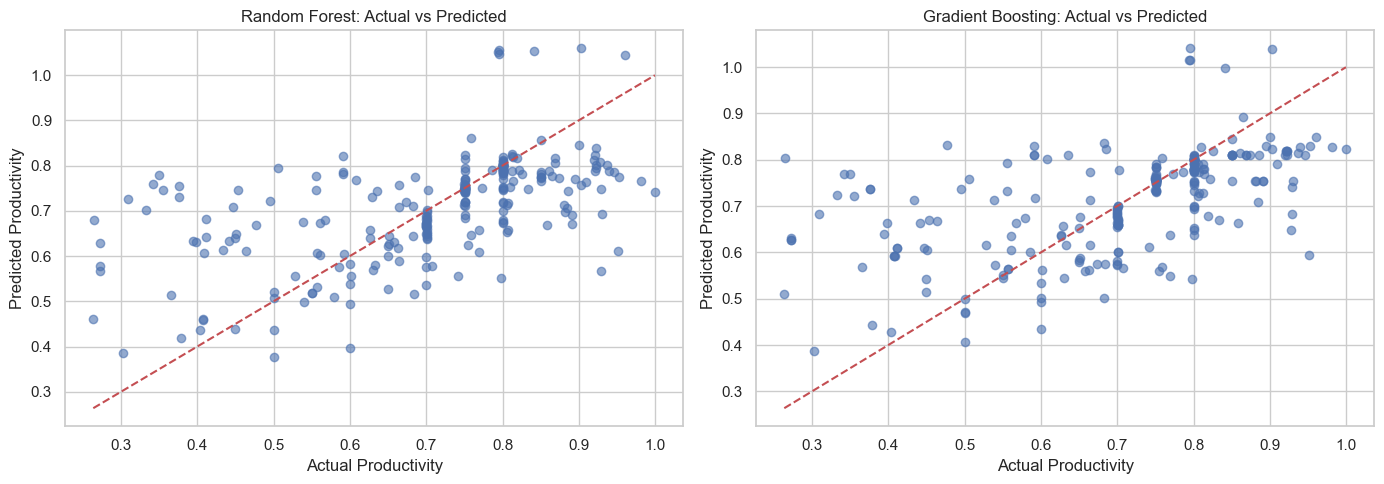

In [42]:
plt.figure(figsize=(14, 5))

for i, model_name in enumerate(
    ["Random Forest", "Gradient Boosting"], 1
):

    plt.subplot(1, 2, i)

    y_pred = predictions[model_name]

    plt.scatter(y_test, y_pred, alpha=0.6)

    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )

    plt.xlabel("Actual Productivity")
    plt.ylabel("Predicted Productivity")
    plt.title(f"{model_name}: Actual vs Predicted")

plt.tight_layout()
plt.show()

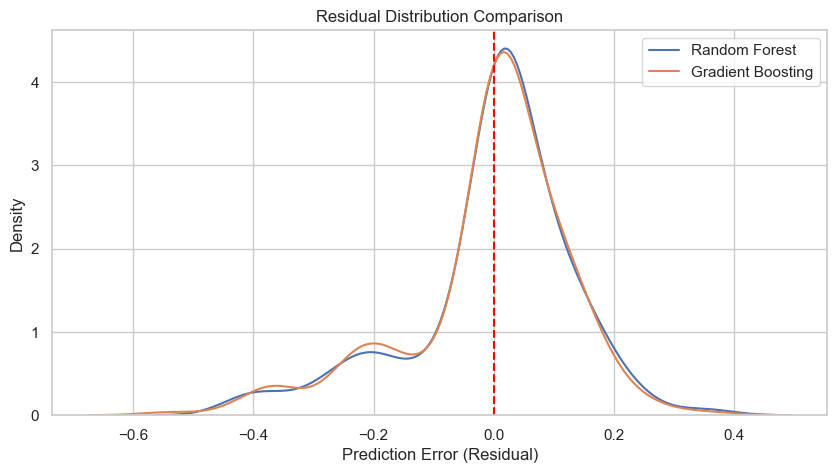

In [43]:
plt.figure(figsize=(10, 5))

for model_name in ["Random Forest", "Gradient Boosting"]:

    residuals = y_test.values - predictions[model_name]

    sns.kdeplot(
        residuals,
        label=model_name,
        fill=False
    )

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Prediction Error (Residual)")
plt.ylabel("Density")
plt.title("Residual Distribution Comparison")
plt.legend()
plt.show()